# Import Library and Dataset

In [1]:
import pandas as pd
import numpy as np

# Load Dataset
df = pd.read_csv('retail_price.csv')

# Menampilkan informasi dasar dataset
print(f"Bentuk Dataset: {df.shape}")
print("\n5 Baris Pertama Data:")
df.head()

Bentuk Dataset: (676, 30)

5 Baris Pertama Data:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.95,39,161,2,...,89.9,3.9,15.011897,215.000000,4.4,8.760000,45.95,4.0,15.100000,45.90
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.95,39,161,2,...,89.9,3.9,14.769216,209.000000,4.4,21.322000,45.95,4.0,12.933333,45.95
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.95,39,161,2,...,89.9,3.9,13.993833,205.000000,4.4,22.195932,45.95,4.0,14.840000,45.95
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.287500,45.95,39,161,2,...,89.9,3.9,14.656757,199.509804,4.4,19.412885,45.95,4.0,14.287500,45.95
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.100000,45.95,39,161,2,...,89.9,3.9,18.776522,163.398710,4.4,24.324687,45.95,4.0,15.100000,45.95


# EDA

In [2]:
# Mengecek informasi kolom, tipe data, dan missing values
print("--- INFO DATASET ---")
df.info()

print("\n--- DESKRIPSI STATISTIK TARGET (QTY) ---")
print(df['qty'].describe())

# Mengecek 10 fitur dengan korelasi tertinggi terhadap jumlah penjualan (qty)
print("\n--- KORELASI TERHADAP QTY ---")
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()['qty'].sort_values(ascending=False)
print(corr.head(10))

--- INFO DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  676 non-null    object 
 1   product_category_name       676 non-null    object 
 2   month_year                  676 non-null    object 
 3   qty                         676 non-null    int64  
 4   total_price                 676 non-null    float64
 5   freight_price               676 non-null    float64
 6   unit_price                  676 non-null    float64
 7   product_name_lenght         676 non-null    int64  
 8   product_description_lenght  676 non-null    int64  
 9   product_photos_qty          676 non-null    int64  
 10  product_weight_g            676 non-null    int64  
 11  product_score               676 non-null    float64
 12  customers                   676 non-null    int64  
 13  weekday       

# Feature Engineering

In [3]:
# Fungsi untuk membuat fitur-fitur baru (interaksi harga, kompetitor, ongkir, dll)
def create_advanced_features(data):
    df_feat = data.copy()
    
    # A. Competitor Price Differences & Ratios
    df_feat['comp_price_avg'] = df_feat[['comp_1', 'comp_2', 'comp_3']].mean(axis=1)
    df_feat['price_diff_vs_comp_avg'] = df_feat['unit_price'] - df_feat['comp_price_avg']
    df_feat['price_ratio_comp1'] = df_feat['unit_price'] / (df_feat['comp_1'] + 1e-5)
    df_feat['is_cheapest'] = (df_feat['unit_price'] < df_feat[['comp_1', 'comp_2', 'comp_3']].min(axis=1)).astype(int)
    
    # B. Freight & Total Cost Ratios
    df_feat['freight_ratio'] = df_feat['freight_price'] / (df_feat['unit_price'] + 1e-5)
    
    # C. Price Change Dynamics
    df_feat['price_change_pct'] = (df_feat['unit_price'] - df_feat['lag_price']) / (df_feat['lag_price'] + 1e-5)
    
    # D. Competitor Score & Rating Gap
    df_feat['comp_score_avg'] = df_feat[['ps1', 'ps2', 'ps3']].mean(axis=1)
    df_feat['score_diff_vs_comp'] = df_feat['product_score'] - df_feat['comp_score_avg']
    
    return df_feat

# Eksekusi Feature Engineering
df_engineered = create_advanced_features(df)
print(f"Jumlah kolom setelah Feature Engineering: {df_engineered.shape[1]}")

Jumlah kolom setelah Feature Engineering: 38


# Data Preprocessing & Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separasi Target & Features
X = df_engineered.drop(columns=['qty', 'total_price', 'month_year', 'product_id'])
y = df_engineered['qty']

cat_cols = ['product_category_name']
num_cols = [col for col in X.columns if col not in cat_cols]

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['product_category_name']
)

# Pipeline Column Transformer
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Fit pada Data Train & Transformasi Data Train-Test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Ekstraksi Nama Kolom Hasil Preprocessing
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + encoded_cat_cols

print(f"Bentuk X_train setelah preprocessing: {X_train_prep.shape}")
print(f"Bentuk X_test setelah preprocessing : {X_test_prep.shape}")

Bentuk X_train setelah preprocessing: (540, 42)
Bentuk X_test setelah preprocessing : (136, 42)


# Model Building & Hyperparameter Tuning

In [5]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Parameter Grid untuk Tuning
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'min_samples_split': [2, 5]
}

# Grid Search Cross Validation
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Fitting Model
grid_search.fit(X_train_prep, y_train)
best_model = grid_search.best_estimator_

# Evaluasi Performance
y_pred = best_model.predict(X_test_prep)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hyperparameter Terbaik: {grid_search.best_params_}")
print(f"Test Set R2 Score    : {r2:.4f}")
print(f"Test Set RMSE        : {rmse:.4f}")
print(f"Test Set MAE         : {mae:.4f}")

Hyperparameter Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 200}
Test Set R2 Score    : 0.4241
Test Set RMSE        : 13.0939
Test Set MAE         : 7.1524


# Feature Importance Analysis

In [6]:
# Ekstraksi Tingkat Kepentingan Fitur
importances = best_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- TOP 10 FITUR PALING BERPENGARUH ---")
print(feature_imp_df.head(10))

--- TOP 10 FITUR PALING BERPENGARUH ---
                   Feature  Importance
13                       s    0.347957
7                customers    0.207187
14                  volume    0.050244
0            freight_price    0.049396
27       price_ratio_comp1    0.044798
5         product_weight_g    0.044153
4       product_photos_qty    0.043571
18                  comp_2    0.027884
30        price_change_pct    0.025103
26  price_diff_vs_comp_avg    0.024532


C:\Users\Radja Triyasa\AppData\Local\Temp\ipykernel_20904\2476139289.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


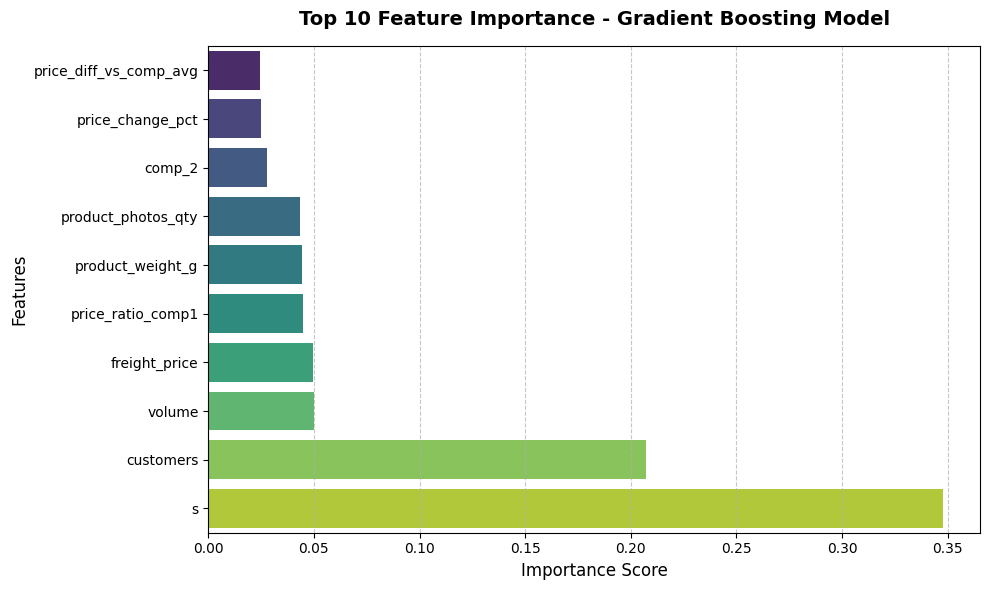

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil Top 10 Fitur Terpenting
top10_features = feature_imp_df.head(10).sort_values(by='Importance', ascending=True)

# Membuat Visualisasi Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=top10_features, 
    palette='viridis'
)

# Menambahkan Judul dan Label Axis
plt.title('Top 10 Feature Importance - Gradient Boosting Model', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Tampilkan Grafik
plt.tight_layout()
plt.show()

# Dynamic Price Optimization Simulation

In [8]:
def simulate_price_elasticity(sample_row_idx, model, preprocessor, feature_names):
    sample_data = X_test.iloc[[sample_row_idx]].copy()
    original_price = sample_data['unit_price'].values[0]
    
    # Variasi multiplier harga (-20% s/d +20%)
    price_multipliers = np.linspace(0.8, 1.2, 9)
    results = []
    
    for m in price_multipliers:
        temp_df = sample_data.copy()
        new_price = original_price * m
        temp_df['unit_price'] = new_price
        
        # Recalculate fitur interaksi berdasarkan harga baru
        temp_df['price_diff_vs_comp_avg'] = new_price - temp_df['comp_price_avg']
        temp_df['price_ratio_comp1'] = new_price / (temp_df['comp_1'] + 1e-5)
        temp_df['freight_ratio'] = temp_df['freight_price'] / (new_price + 1e-5)
        
        # Transform & Predict QTY
        prep_sample = preprocessor.transform(temp_df)
        predicted_qty = model.predict(prep_sample)[0]
        predicted_revenue = new_price * predicted_qty
        
        results.append({
            'Price_Multiplier': f"{int((m-1)*100)}%",
            'New_Price': round(new_price, 2),
            'Predicted_Qty': round(predicted_qty, 2),
            'Predicted_Revenue': round(predicted_revenue, 2)
        })
        
    return pd.DataFrame(results)

# Simulasi pada Sampel Pertama di Test Set
sim_results = simulate_price_elasticity(0, best_model, preprocessor, all_feature_names)

print("--- HASIL SIMULASI ELASTISITAS HARGA ---")
print(sim_results)

# Menentukan Harga Optimal
optimal_row = sim_results.loc[sim_results['Predicted_Revenue'].idxmax()]
print("\n=== REKOMENDASI HARGA OPTIMAL ===")
print(f"Harga Original          : {sim_results.loc[sim_results['Price_Multiplier']=='0%', 'New_Price'].values[0]}")
print(f"Harga Optimal Rekomendasi: {optimal_row['New_Price']} ({optimal_row['Price_Multiplier']})")
print(f"Estimasi Revenue Maksimal: {optimal_row['Predicted_Revenue']}")

--- HASIL SIMULASI ELASTISITAS HARGA ---
  Price_Multiplier  New_Price  Predicted_Qty  Predicted_Revenue
0             -19%      15.99          13.99             223.69
1             -14%      16.99          13.99             237.67
2              -9%      17.99          14.17             254.90
3              -5%      18.99          14.17             269.07
4               0%      19.99          15.08             301.38
5               5%      20.99          14.53             304.99
6              10%      21.99          17.07             375.46
7              14%      22.99          15.12             347.63
8              19%      23.99          14.63             350.93

=== REKOMENDASI HARGA OPTIMAL ===
Harga Original          : 19.99
Harga Optimal Rekomendasi: 21.99 (10%)
Estimasi Revenue Maksimal: 375.46
